# Урок 9. Анализ фотографии через Computer Vision

Практическая работа состоит из двух частей. Сначала фотография разбирается
классическими методами OpenCV: перевод в оттенки серого, размытие, выделение
границ алгоритмом Canny, поиск контуров и сбор таблицы признаков. Затем та же
фотография подаётся в готовую модель YOLO, и результаты двух подходов
сравниваются.

In [1]:
import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.width", 130)
pd.set_option("display.max_columns", 20)


def show(image, title, cmap=None, size=(7, 8)):
    plt.figure(figsize=size)
    plt.imshow(image, cmap=cmap)
    plt.title(title)
    plt.axis("off")
    plt.tight_layout()
    plt.show()

## 1. Загрузка изображения

OpenCV читает картинку в порядке каналов BGR, а matplotlib ожидает RGB,
поэтому перед показом каналы переставляются.

Размер изображения: (1080, 810, 3)
Высота: 1080 | Ширина: 810 | Каналов: 3


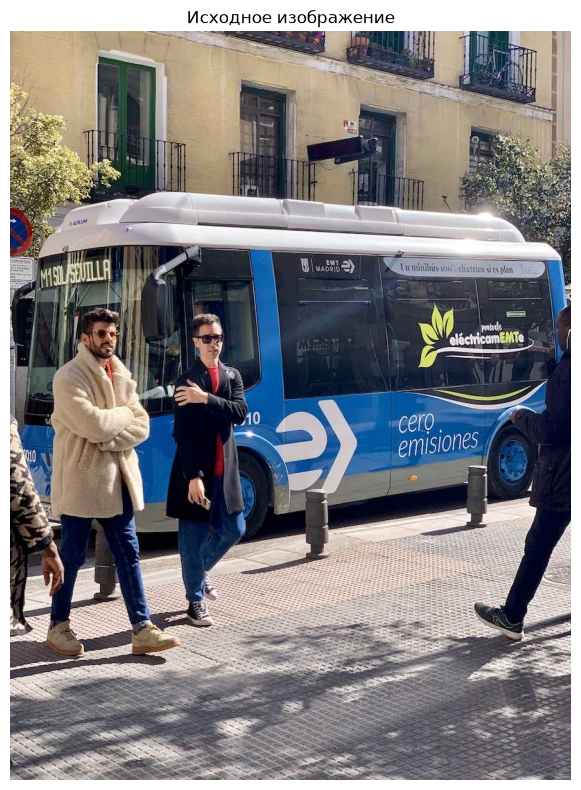

In [2]:
image = cv2.imread("photo.jpg")
print("Размер изображения:", image.shape)
print("Высота:", image.shape[0], "| Ширина:", image.shape[1], "| Каналов:", image.shape[2])

rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
show(rgb, "Исходное изображение")

## 2. Перевод в grayscale

Цвет для поиска границ не нужен: важен перепад яркости. Один канал вместо трёх
упрощает обработку и ускоряет её втрое.

Размер после перевода: (1080, 810)


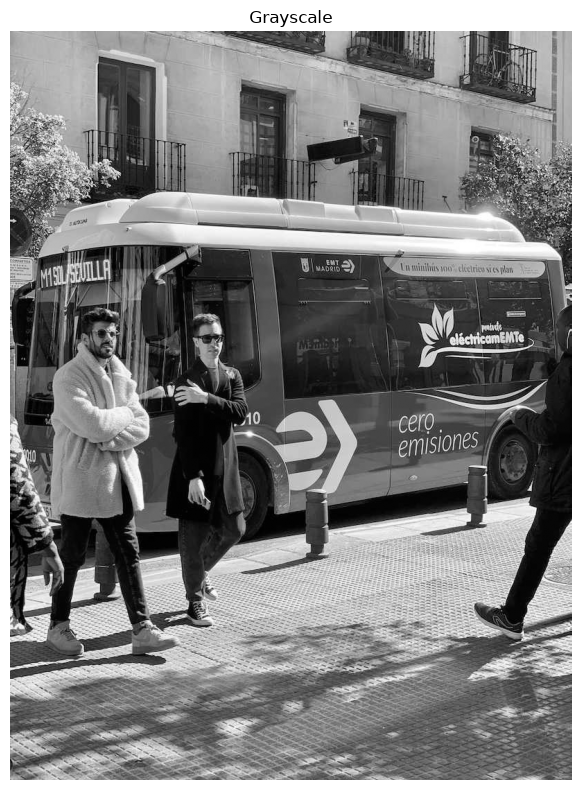

In [3]:
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
print("Размер после перевода:", gray.shape)
show(gray, "Grayscale", cmap="gray")

## 3. Размытие

Гауссово размытие убирает мелкий шум и текстуру. Без него Canny найдёт тысячи
ложных границ на каждой неровности.

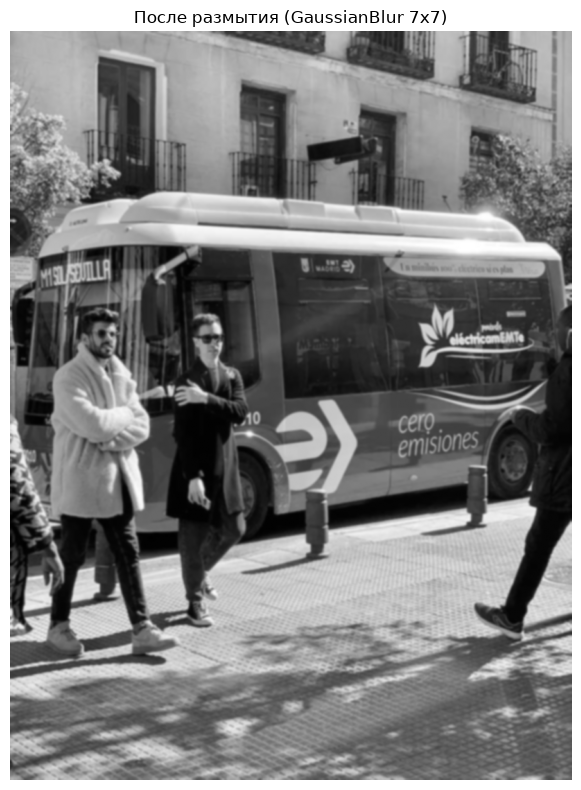

In [4]:
blurred = cv2.GaussianBlur(gray, (7, 7), 0)
show(blurred, "После размытия (GaussianBlur 7x7)", cmap="gray")

## 4. Границы объектов через Canny

Пикселей-границ: 60183


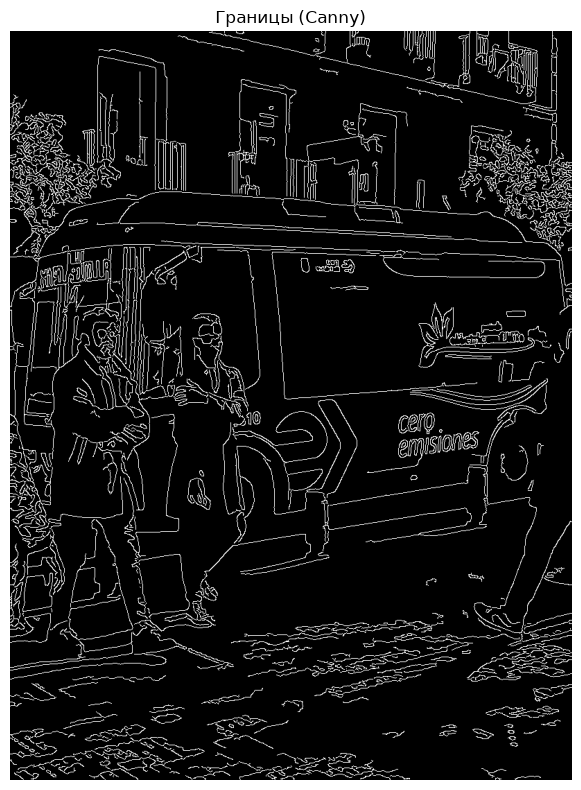

In [5]:
edges = cv2.Canny(blurred, threshold1=50, threshold2=150)
print("Пикселей-границ:", int((edges > 0).sum()))
show(edges, "Границы (Canny)", cmap="gray")

## 5. Поиск контуров и рамки

Canny часто оставляет границу разорванной: тень или блик разрезают контур объекта
на куски. Перед поиском контуров границы расширяются морфологической операцией
`dilate`, которая смыкает мелкие разрывы, иначе один объект распадётся на десятки
обрывков.

Дальше контуры фильтруются по площади и минимальной стороне: мелкие пятна шума
отбрасываются, остаются крупные осмысленные области.

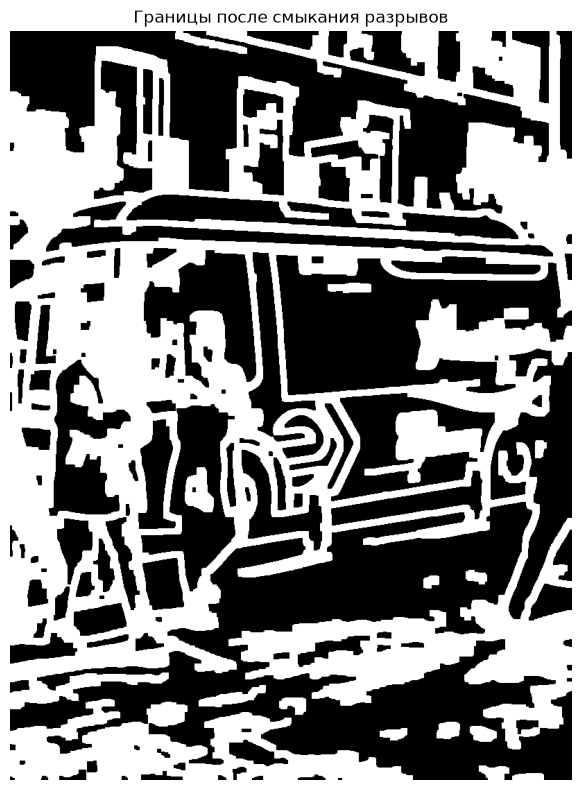

In [6]:
kernel = np.ones((5, 5), np.uint8)
closed = cv2.dilate(edges, kernel, iterations=2)
closed = cv2.morphologyEx(closed, cv2.MORPH_CLOSE, kernel)
show(closed, "Границы после смыкания разрывов", cmap="gray")

In [7]:
contours, _ = cv2.findContours(closed, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
print("Найдено контуров всего:", len(contours))

MIN_AREA = 600
MIN_SIDE = 20

kept = []
for contour in contours:
    area = cv2.contourArea(contour)
    x, y, w, h = cv2.boundingRect(contour)

    if area < MIN_AREA or w < MIN_SIDE or h < MIN_SIDE:
        continue

    kept.append((contour, x, y, w, h, area))

print("Осталось после фильтрации:", len(kept))

Найдено контуров всего: 14
Осталось после фильтрации: 8


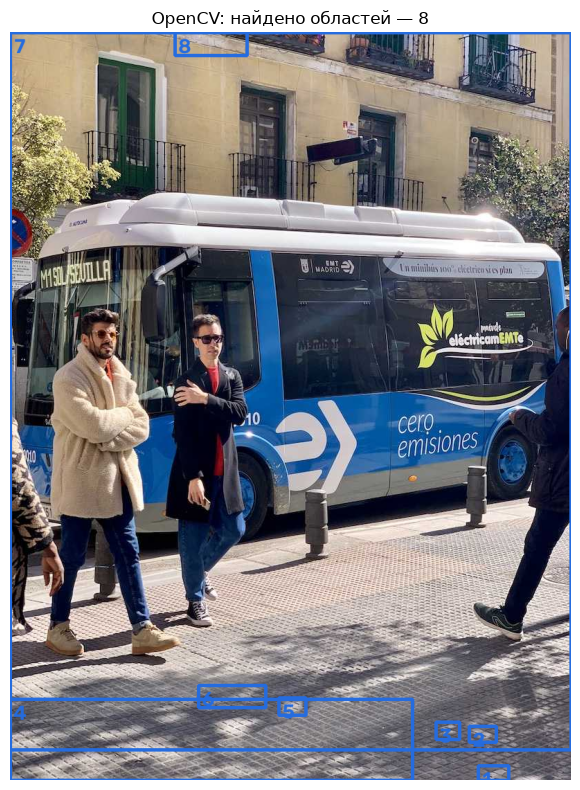

In [8]:
boxed = rgb.copy()
for i, (_, x, y, w, h, _) in enumerate(kept, 1):
    cv2.rectangle(boxed, (x, y), (x + w, y + h), (37, 108, 223), 3)
    cv2.putText(boxed, str(i), (x + 5, y + 30), cv2.FONT_HERSHEY_SIMPLEX, 1.0, (37, 108, 223), 2)

show(boxed, f"OpenCV: найдено областей — {len(kept)}")

## 6. Таблица признаков по найденным областям

In [9]:
rows = []
crops = []

for i, (contour, x, y, w, h, area) in enumerate(kept, 1):
    crop = gray[y:y + h, x:x + w]
    crops.append(rgb[y:y + h, x:x + w])

    rows.append({
        "region": i,
        "x": x,
        "y": y,
        "width": w,
        "height": h,
        "area": round(area, 1),
        "perimeter": round(cv2.arcLength(contour, True), 1),
        "mean_brightness": round(float(crop.mean()), 1),
    })

features = pd.DataFrame(rows)
features

,region,x,y,width,height,area,perimeter,mean_brightness
0,1,676,1059,44,21,627.0,120.6,121.0
1,2,663,1002,39,23,652.5,107.7,115.3
2,3,615,996,34,25,663.0,105.8,105.6
3,4,0,963,581,117,34193.5,2448.1,126.6
4,5,388,961,39,25,636.0,123.5,131.3
5,6,272,943,97,32,1253.0,237.7,116.8
6,7,0,0,810,1036,535057.5,14756.8,116.0
7,8,238,0,104,33,1052.0,245.4,163.3


In [10]:
features.describe().round(1)

,region,x,y,width,height,area,perimeter,mean_brightness
count,8.0,8.0,8.0,8.0,8.0,8.0,8.0,8.0
mean,4.5,356.5,740.5,218.5,164.0,71766.8,2268.2,124.5
std,2.4,277.5,458.4,301.9,353.8,187561.9,5109.8,17.5
min,1.0,0.0,0.0,34.0,21.0,627.0,105.8,105.6
25%,2.8,178.5,707.2,39.0,24.5,648.4,117.4,115.8
50%,4.5,330.0,962.0,70.5,28.5,857.5,180.6,118.9
75%,6.2,627.0,997.5,223.2,54.0,9488.1,796.1,127.8
max,8.0,676.0,1059.0,810.0,1036.0,535057.5,14756.8,163.3


### Вырезанные области

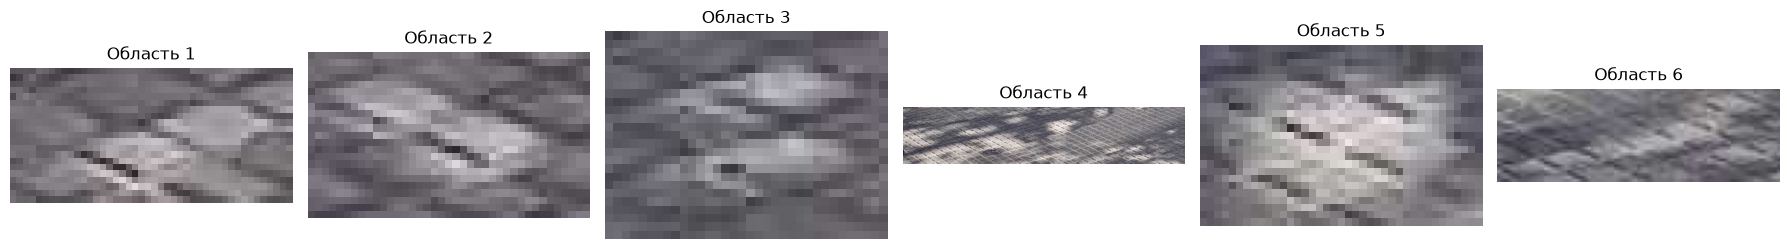

In [11]:
show_count = min(len(crops), 6)
if show_count:
    fig, axes = plt.subplots(1, show_count, figsize=(3 * show_count, 3.5))
    axes = np.atleast_1d(axes)
    for ax, crop, idx in zip(axes, crops, range(1, show_count + 1)):
        ax.imshow(crop)
        ax.set_title(f"Область {idx}")
        ax.axis("off")
    plt.tight_layout()
    plt.show()

## 7. Готовая AI-модель YOLO

YOLO обучена на датасете COCO и умеет не просто находить области, а называть
объекты. Веса `yolov8n.pt` — самая лёгкая версия, её достаточно для демонстрации.

In [12]:
from ultralytics import YOLO

model = YOLO("yolov8n.pt")
results = model(image, verbose=False)[0]

print("Найдено объектов:", len(results.boxes))

Найдено объектов: 6


In [13]:
detections = []
for box in results.boxes:
    x1, y1, x2, y2 = box.xyxy[0].tolist()
    detections.append({
        "object": results.names[int(box.cls[0])],
        "confidence": round(float(box.conf[0]), 3),
        "x1": round(x1), "y1": round(y1),
        "x2": round(x2), "y2": round(y2),
        "width": round(x2 - x1),
        "height": round(y2 - y1),
    })

yolo_table = pd.DataFrame(detections).sort_values("confidence", ascending=False).reset_index(drop=True)
yolo_table

,object,confidence,x1,y1,x2,y2,width,height
0,bus,0.873,23,231,805,757,782,526
1,person,0.866,49,399,245,903,197,504
2,person,0.853,669,392,810,877,140,485
3,person,0.825,222,406,345,858,123,452
4,person,0.261,0,551,63,873,63,323
5,stop sign,0.255,0,254,33,325,32,70


In [14]:
for row in detections:
    print(f"{row['object']:<12} confidence={row['confidence']:.3f}  "
          f"рамка=({row['x1']}, {row['y1']}) - ({row['x2']}, {row['y2']})")

bus          confidence=0.873  рамка=(23, 231) - (805, 757)
person       confidence=0.866  рамка=(49, 399) - (245, 903)
person       confidence=0.853  рамка=(669, 392) - (810, 877)
person       confidence=0.825  рамка=(222, 406) - (345, 858)
person       confidence=0.261  рамка=(0, 551) - (63, 873)
stop sign    confidence=0.255  рамка=(0, 254) - (33, 325)


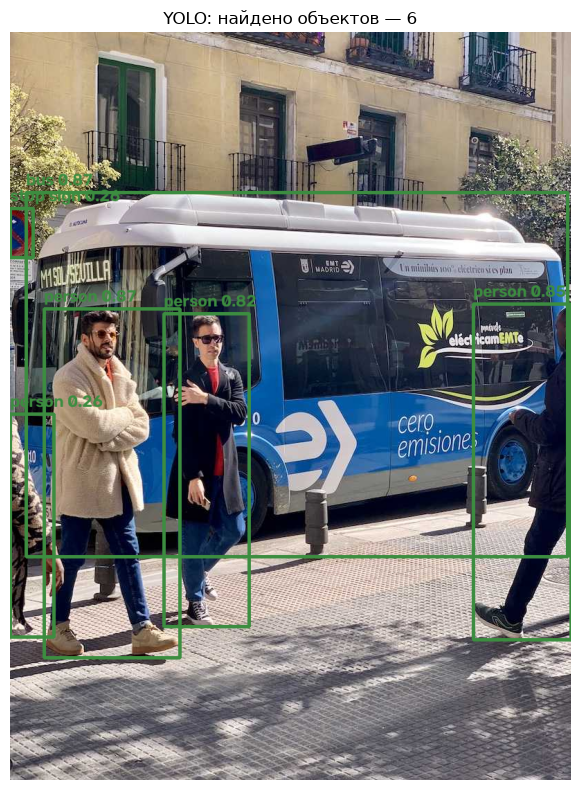

In [15]:
yolo_image = rgb.copy()
for row in detections:
    cv2.rectangle(yolo_image, (row["x1"], row["y1"]), (row["x2"], row["y2"]), (60, 141, 64), 3)
    label = f"{row['object']} {row['confidence']:.2f}"
    cv2.putText(yolo_image, label, (row["x1"], max(row["y1"] - 10, 20)),
                cv2.FONT_HERSHEY_SIMPLEX, 0.8, (60, 141, 64), 2)

show(yolo_image, f"YOLO: найдено объектов — {len(detections)}")

## 8. Сравнение подходов

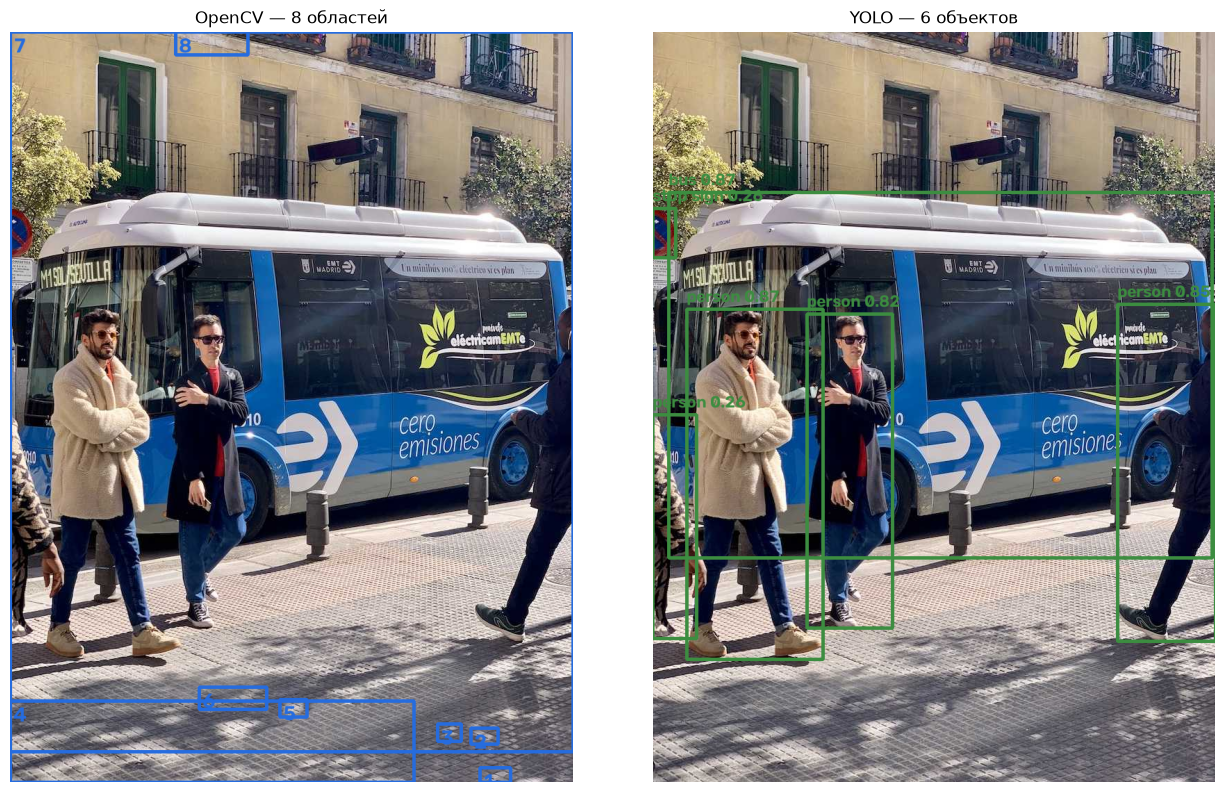

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 8))
axes[0].imshow(boxed)
axes[0].set_title(f"OpenCV — {len(kept)} областей")
axes[0].axis("off")
axes[1].imshow(yolo_image)
axes[1].set_title(f"YOLO — {len(detections)} объектов")
axes[1].axis("off")
plt.tight_layout()
plt.show()

In [17]:
print(f"OpenCV нашёл областей:   {len(kept)}")
print(f"YOLO нашла объектов:     {len(detections)}")
print(f"\nЧто назвала YOLO: {sorted(set(d['object'] for d in detections))}")
print(f"Средняя уверенность: {np.mean([d['confidence'] for d in detections]):.3f}")

OpenCV нашёл областей:   8
YOLO нашла объектов:     6

Что назвала YOLO: ['bus', 'person', 'stop sign']
Средняя уверенность: 0.655


## Вывод

**Что смог найти OpenCV.** Классический подход выделил области с сильным
перепадом яркости: границы объектов, крупные однородные пятна, резкие контрасты
между предметом и фоном. Он честно ответил на вопрос «где на картинке что-то
есть», но не имеет ни малейшего представления о том, что именно он нашёл. Для
OpenCV область с автобусом и область с тенью на асфальте одинаковы: и то, и
другое — замкнутый контур с определённой площадью и периметром.

**Что смогла определить YOLO.** Модель не просто нашла области, а назвала
объекты и указала уверенность для каждого. Она разделила людей и транспорт,
хотя по пикселям эти области ничем принципиально не отличаются от остальных.

**Где были ошибки.** У OpenCV они видны прямо в таблице признаков. Самая крупная
найденная область занимает практически весь кадр: после смыкания границ контур
автобуса слился с фоном и краями изображения в один огромный прямоугольник.
Несколько других областей, наоборот, оказались мелкими фрагментами по 600–1200
пикселей — это куски разметки и теней, не соответствующие никакому объекту.

То есть обе типичные беды проявились сразу: один объект распадается на куски,
а разные объекты сливаются в одну область. Результат сильно зависит от
подобранных вручную порогов Canny, размера ядра размытия и числа итераций
dilate. До смыкания разрывов фильтр оставлял всего одну область из 824 контуров,
после — восемь из четырнадцати. Ни одно из этих чисел не отражает реального
количества объектов на фотографии.
У YOLO ошибки другого рода: она может пропустить мелкий или частично закрытый
объект и иногда присваивает невысокую уверенность тому, что человек распознаёт
мгновенно.

**Почему результаты отличаются.** Это два принципиально разных способа смотреть
на изображение. OpenCV работает с пикселями по жёстким правилам, которые задал
программист: найти перепад яркости, замкнуть контур, отфильтровать по площади.
Никакого знания о мире у него нет. YOLO использует обученную на размеченных
фотографиях нейросеть: она выучила, как выглядят восемьдесят классов объектов,
и ищет на картинке знакомые образы, а не просто границы.

**Главный вывод.** OpenCV помогает находить границы и области изображения через
пиксели и правила, а YOLO использует обученную модель и может определять, что
именно находится на фотографии. Классические методы остаются полезными там, где
задача формальная и условия съёмки стабильны: измерить размер детали, найти
документ на столе, отследить движение. Как только требуется назвать объект,
нужна обученная модель.